# Functional grid-module clusters from pairwise XGBoost coupling

Tests whether grid modules (HDBSCAN on spacing/orientation, precomputed in
`data/cell_classifications.csv`) show up as clusters in a *functionally derived*
coupling graph built from the pairwise XGBoost assay
(`scripts/figures/xgboost_pairwise_assay.py`), and whether non-grid cells can be
attributed to a specific module via that coupling.

## Exact questions this notebook answers

1. **Do grid cells belonging to the same (spacing/orientation-defined) grid module
   show higher pairwise explained variance than grid cells in different modules?**
   Tested for both (a) raw pR² (single covariate cell only, no behaviour) and
   (b) Δ pR² (behaviour-controlled — position/speed/HD/theta removed, so shared
   tuning cannot produce the effect). A label-permutation test (shuffling true
   module identity among the grid cells) gives a p-value for each.
2. **Does unsupervised community detection (Leiden, run independently on the raw
   and Δ pR² graphs, without ever being told the true module labels) recover the
   same module structure?** Quantified via the contingency between Leiden
   clusters and true module, and Leiden's modularity Q.
3. **Can non-grid cells (non-grid-spatial / non-spatial) be attributed to a
   specific grid module**, based on which module's grid cells they couple to
   most strongly? Tested two ways: (a) directly — nearest-module mean Δ pR²,
   with a permutation test against randomly-relabelled modules — and (b) via
   Leiden — do non-grid cells fall into the same community as a module's grid
   cells, or do they form their own free-floating clusters?
4. **Is this consistent across behavioural contexts?** For the one session
   recorded in both VR and OF1, do cells keep the same Leiden cluster
   assignment in both (Adjusted Rand Index)? Consistency across task argues
   module structure is a circuit property rather than a task-driven artefact.
5. **Does controlling for behaviour change the answer?** If raw pR² shows
   within/cross-module separation but Δ pR² does not, the apparent clustering
   is just shared spatial tuning. If both show it, module structure survives
   removing tuning — the more interesting result.

## Session selection

Screened all mouse/day sessions with cached pairwise-assay CSVs
(`data/eddie/xgboost_pairwise/`, history=100ms) against the grid-module labels
in `cell_classifications.csv`, looking for sessions with (a) many grid cells,
(b) both HDBSCAN modules (0 and 1) represented, and (c) most of those cells
actually processed as *targets* (not just covariates) so the coupling matrix
is reasonably complete. Picked:

| mouse | day | session types | n GC | module split (0 / 1) | notes |
|---|---|---|---|---|---|
| 26 | 19 | VR (full), OF1 (partial) | 47 | 38 / 3 | only dual VR+OF1 session available; OF1 missing module-1 cells as *targets* (still present as covariates) |
| 25 | 25 | OF1 (full) | 44 | 35 / 7 | largest single-session grid-cell count |
| 21 | 26 | OF1 (near-full) | 32 | 20 / 7 | most balanced module split |

All three modules are imbalanced (module 1 is always the minority) because
this cohort's HDBSCAN module detection only ever separates 2 modules per
session in the cached classification — flagged where it affects test power.

In [1]:
import numpy as np
import pandas as pd
import glob
import os
import igraph as ig
import leidenalg
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
import warnings
warnings.filterwarnings('ignore')

%load_ext autoreload
%autoreload 2
%matplotlib inline
plt.rcParams['font.family'] = 'Arial'

DATA_PATH = '/Users/harryclark/Documents/spatial-manifolds/data/eddie/xgboost_pairwise/'
CC_PATH   = '/Users/harryclark/Documents/spatial-manifolds/data/cell_classifications.csv'
FIG_PATH  = '/Users/harryclark/Documents/spatial-manifolds/scripts/figures/figure_playground/module_clusters/'
os.makedirs(FIG_PATH, exist_ok=True)

HISTORY_LENGTH = 100  # matches the cached pairwise CSVs (h100) -- do NOT change without re-running the assay

# (mouse, day) chosen for high grid-cell counts with both HDBSCAN grid modules represented (see markdown above)
SESSIONS = [
    dict(mouse=26, day=19, sessions=['VR', 'OF1']),
    dict(mouse=25, day=25, sessions=['OF1']),
    dict(mouse=21, day=26, sessions=['OF1']),
]

# richest behavioural baseline per session type (removes shared tuning -> isolates coupling)
RICH_BASELINE = {'VR': 'pos_speed_lfp', 'OF1': 'pos_speed_hd_hing_lfp'}
RAW_BASELINE  = 'null'   # "cell only" -- no behaviour removed

N_PERM   = 1000
RNG_SEED = 42

GROUP_COLORS = {
    'Module 0 (GC)':    '#c0392b',
    'Module 1 (GC)':    '#2980b9',
    'GC (unassigned)':  '#8e44ad',
    'Non-grid spatial': '#27ae60',
    'Other':            '#7f8c8d',
}
GROUP_ORDER = list(GROUP_COLORS.keys())

## 1. Load grid-module ground truth and pairwise-assay results

In [2]:
cc = pd.read_csv(CC_PATH, low_memory=False)
cc['mouse']      = cc['mouse'].astype(int)
cc['day']        = cc['day'].astype(int)
cc['cluster_id'] = cc['cluster_id'].astype(int)


def get_module_labels(mouse, day):
    '''cluster_id -> dict(cell_type='GC'/'NG'/'Other', module=0/1/-1).
    module is only meaningful for cell_type=='GC'; -1 = unassigned by HDBSCAN
    (or not a grid cell).'''
    sub = cc[(cc.mouse == mouse) & (cc.day == day)].drop_duplicates('cluster_id')
    out = {}
    for _, r in sub.iterrows():
        mod = int(r['grid_module']) if pd.notna(r['grid_module']) else -1
        out[int(r['cluster_id'])] = dict(cell_type=r['cell_type'], module=mod)
    return out


def load_pairwise(mouse, day, session_type, history_length=HISTORY_LENGTH, data_path=DATA_PATH):
    pattern = os.path.join(data_path, f'xgboost_pairwise_M{mouse}_D{day}_h{history_length}_{session_type}_*.csv')
    files = sorted(glob.glob(pattern))
    if not files:
        return None
    # keep_default_na=False: pandas' default NA sniffing treats the literal
    # string "null" (one of our baseline names) as a missing value otherwise.
    df = pd.concat([pd.read_csv(f, keep_default_na=False) for f in files], ignore_index=True)
    return df

## 2. Build the raw and Δ pR² matrices

Both matrices use the identical construction
(`pR2(baseline + covariate) − pR2(baseline alone)`, directed then symmetrised
by averaging both directions) — they differ only in which baseline is
conditioned on:

- **raw pR² ("cell only")**: `baseline='null'` — no behaviour at all, so this
  reflects everything two cells share, including spatial tuning overlap.
- **Δ pR² (coupling)**: `baseline=` the richest available behavioural set
  (position + speed + HD + theta) — removes shared tuning, so what's left is
  closer to genuine functional coupling.

In [3]:
def build_pr2_matrix(pw_df, baseline):
    bl = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id == -1)]
          [['target_cluster_id', 'pR2_cv']].rename(columns={'pR2_cv': 'pR2_baseline'})
          .drop_duplicates('target_cluster_id'))
    cv = (pw_df[(pw_df.baseline == baseline) & (pw_df.covariate_cluster_id >= 0)]
          [['target_cluster_id', 'covariate_cluster_id', 'pR2_cv']].copy())
    merged = cv.merge(bl, on='target_cluster_id', how='inner')
    merged['d'] = merged['pR2_cv'] - merged['pR2_baseline']

    all_ids = sorted(set(merged.target_cluster_id) | set(merged.covariate_cluster_id))
    idx = {cid: i for i, cid in enumerate(all_ids)}
    N = len(all_ids)
    mat = np.full((N, N), np.nan)
    for row in merged.itertuples(index=False):
        i = idx[int(row.covariate_cluster_id)]
        j = idx[int(row.target_cluster_id)]
        mat[i, j] = row.d
    np.fill_diagonal(mat, 0)
    sym = np.nanmean(np.stack([mat, mat.T]), axis=0)
    sym = np.nan_to_num(sym, nan=0.0)
    return sym, mat, all_ids


def build_session_matrices(pw_df, session_type):
    for b in (RAW_BASELINE, RICH_BASELINE[session_type]):
        if b not in pw_df['baseline'].unique():
            raise ValueError(f'baseline "{b}" not found in this session pairwise CSVs')
    raw_sym, raw_dir, ids_raw = build_pr2_matrix(pw_df, RAW_BASELINE)
    delta_sym, delta_dir, ids_delta = build_pr2_matrix(pw_df, RICH_BASELINE[session_type])
    assert ids_raw == ids_delta, 'cell id sets differ between baselines -- unexpected'
    return raw_sym, raw_dir, delta_sym, delta_dir, ids_raw

## 3. Grouping, plotting, Leiden clustering and statistics helpers

In [4]:
def cell_group_order(cell_ids, mod_labels):
    groups = []
    for cid in cell_ids:
        info = mod_labels.get(cid, dict(cell_type='Other', module=-1))
        if info['cell_type'] == 'GC' and info['module'] == 0:
            g = 'Module 0 (GC)'
        elif info['cell_type'] == 'GC' and info['module'] == 1:
            g = 'Module 1 (GC)'
        elif info['cell_type'] == 'GC':
            g = 'GC (unassigned)'
        elif info['cell_type'] == 'NG':
            g = 'Non-grid spatial'
        else:
            g = 'Other'
        groups.append(g)
    order = sorted(range(len(cell_ids)), key=lambda i: GROUP_ORDER.index(groups[i]))
    sorted_groups = [groups[i] for i in order]
    return order, sorted_groups


def plot_matrix_pair(raw_sym, delta_sym, cell_ids, mod_labels, title):
    order, groups = cell_group_order(cell_ids, mod_labels)
    bounds = [i for i in range(1, len(groups)) if groups[i] != groups[i - 1]]
    block_starts = [0] + bounds
    block_ends = bounds + [len(groups)]
    tick_pos = [(s + e) / 2 - 0.5 for s, e in zip(block_starts, block_ends)]
    tick_lab = [groups[s] for s in block_starts]

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
    for ax, mat, name in zip(axes, [raw_sym, delta_sym],
                              ['Raw pR² (cell only, baseline=null)', 'Δ pR² (behaviour-controlled coupling)']):
        m = mat[np.ix_(order, order)]
        vmax = np.nanpercentile(np.abs(m), 98) if np.any(m != 0) else 1.0
        im = ax.imshow(m, cmap='RdBu_r', vmin=-vmax, vmax=vmax, interpolation='nearest', aspect='auto')
        plt.colorbar(im, ax=ax, fraction=0.045, pad=0.02).set_label(name, fontsize=7)
        for b in bounds:
            ax.axhline(b - 0.5, color='k', lw=0.7)
            ax.axvline(b - 0.5, color='k', lw=0.7)
        ax.set_title(name, fontsize=9)
        ax.set_xticks([])
    axes[0].set_yticks(tick_pos)
    axes[0].set_yticklabels(tick_lab, fontsize=7)
    for lab, gname in zip(axes[0].get_yticklabels(), tick_lab):
        lab.set_color(GROUP_COLORS[gname])
    axes[1].set_yticks([])
    fig.suptitle(title, fontsize=11, fontweight='bold')
    plt.tight_layout()
    return fig


def run_leiden(sym_mat, res_min=None, res_max=None, n_search=60, seed=RNG_SEED):
    n = sym_mat.shape[0]
    rows, cols = np.triu_indices(n, k=1)
    weights = sym_mat[rows, cols].tolist()
    g = ig.Graph(n=n, edges=list(zip(rows.tolist(), cols.tolist())), directed=False, edge_attrs={'weight': weights})

    # CPM's resolution parameter is an absolute per-edge-weight threshold, so a
    # fixed range is meaningless here: raw/delta pR2 edge weights are tiny
    # (~1e-3 to 1e-1). Scale the search range from this matrix's own positive
    # edge-weight distribution instead of a hardcoded range.
    if res_min is None or res_max is None:
        pos = np.array(weights)
        pos = pos[pos > 0]
        if len(pos) == 0:
            res_min, res_max = 1e-4, 1e-2
        else:
            res_min = res_min if res_min is not None else max(np.percentile(pos, 10), 1e-6)
            res_max = res_max if res_max is not None else max(np.percentile(pos, 99), res_min * 10)

    resolutions = np.linspace(res_min, res_max, n_search)
    best_mod, best_res = -np.inf, resolutions[0]
    for res in resolutions:
        part = leidenalg.find_partition(g, leidenalg.CPMVertexPartition, weights='weight',
                                        resolution_parameter=res, n_iterations=5, seed=seed)
        if part.modularity > best_mod:
            best_mod, best_res = part.modularity, res
    part = leidenalg.find_partition(g, leidenalg.CPMVertexPartition, weights='weight',
                                    resolution_parameter=best_res, n_iterations=200, seed=seed)
    labels = np.array(part.membership)
    u, c = np.unique(labels, return_counts=True)
    for uu, cc_ in zip(u, c):
        if cc_ < 2:
            labels[labels == uu] = -1
    return labels, best_res, best_mod


def within_cross_permtest(sym_mat, cell_ids, mod_labels, n_perm=N_PERM, seed=RNG_SEED):
    '''Restrict to GC cells with a known module (0/1). Test mean(within) -
    mean(cross) against a null built by permuting module labels among these
    GC cells (matrix values are never touched).'''
    rng = np.random.default_rng(seed)
    gc_idx = [i for i, cid in enumerate(cell_ids)
             if mod_labels.get(cid, {}).get('cell_type') == 'GC'
             and mod_labels.get(cid, {}).get('module', -1) in (0, 1)]
    if len(gc_idx) < 6:
        return None
    labels = np.array([mod_labels[cell_ids[i]]['module'] for i in gc_idx])
    sub = sym_mat[np.ix_(gc_idx, gc_idx)]

    def stat(lab):
        same = (lab[:, None] == lab[None, :]) & ~np.eye(len(lab), dtype=bool)
        diff = lab[:, None] != lab[None, :]
        return np.nanmean(sub[same]) - np.nanmean(sub[diff])

    observed = stat(labels)
    null = np.array([stat(rng.permutation(labels)) for _ in range(n_perm)])
    p = (np.sum(null >= observed) + 1) / (n_perm + 1)
    return dict(observed=observed, null_mean=null.mean(), null_sd=null.std(), p=p, n_gc=len(gc_idx))


def assign_nongrid_cells(sym_mat, cell_ids, mod_labels, n_perm=N_PERM, seed=RNG_SEED):
    '''For every cell that is NOT a labelled grid cell, compute its mean
    coupling to module-0 vs module-1 grid cells, assign to the argmax, and
    test the margin against a null built by permuting the grid cells' module
    labels (breaks the true module<->coupling correspondence, keeps every
    other cell's raw coupling values fixed).'''
    rng = np.random.default_rng(seed)
    gc_idx = [i for i, cid in enumerate(cell_ids)
             if mod_labels.get(cid, {}).get('cell_type') == 'GC'
             and mod_labels.get(cid, {}).get('module', -1) in (0, 1)]
    other_idx = [i for i in range(len(cell_ids)) if i not in set(gc_idx)]
    if len(gc_idx) < 6 or len(other_idx) == 0:
        return None, None
    true_labels = np.array([mod_labels[cell_ids[i]]['module'] for i in gc_idx])

    def margins(lab):
        gc0 = [gc_idx[i] for i in range(len(gc_idx)) if lab[i] == 0]
        gc1 = [gc_idx[i] for i in range(len(gc_idx)) if lab[i] == 1]
        m0 = sym_mat[np.ix_(other_idx, gc0)].mean(axis=1)
        m1 = sym_mat[np.ix_(other_idx, gc1)].mean(axis=1)
        return m0, m1

    m0, m1 = margins(true_labels)
    observed_margin = np.abs(m0 - m1)
    assigned = np.where(m0 > m1, 0, 1)

    null_margins = np.empty((n_perm, len(other_idx)))
    for k in range(n_perm):
        pm0, pm1 = margins(rng.permutation(true_labels))
        null_margins[k] = np.abs(pm0 - pm1)

    p_per_cell = (np.sum(null_margins >= observed_margin[None, :], axis=0) + 1) / (n_perm + 1)
    p_aggregate = (np.sum(null_margins.mean(axis=1) >= observed_margin.mean()) + 1) / (n_perm + 1)

    result_df = pd.DataFrame({
        'cluster_id':        [cell_ids[i] for i in other_idx],
        'cell_type':         [mod_labels.get(cell_ids[i], {}).get('cell_type', 'Other') for i in other_idx],
        'assigned_module':   assigned,
        'mean_to_module0':   m0,
        'mean_to_module1':   m1,
        'margin':            observed_margin,
        'p_value':           p_per_cell,
    }).sort_values('p_value')
    return result_df, p_aggregate


def leiden_module_assignment(labels_leiden, cell_ids, mod_labels):
    '''Majority-vote: for each Leiden cluster with >=1 labelled grid cell,
    assign every OTHER member of that cluster to the majority module.'''
    assignments, purity = {}, {}
    for cl in sorted(set(labels_leiden[labels_leiden >= 0])):
        members = [cell_ids[i] for i in range(len(cell_ids)) if labels_leiden[i] == cl]
        gc_mods = [mod_labels[c]['module'] for c in members
                  if mod_labels.get(c, {}).get('cell_type') == 'GC'
                  and mod_labels.get(c, {}).get('module', -1) in (0, 1)]
        majority = None
        if len(gc_mods) > 0:
            vals, counts = np.unique(gc_mods, return_counts=True)
            majority = int(vals[np.argmax(counts)])
            purity[cl] = counts.max() / len(gc_mods)
        for c in members:
            assignments[c] = majority
    return assignments, purity

## 4. Run the pipeline for each session


===== M26 D19 VR =====


  280 cells total, 47 GC, 41 with known module (0/1)


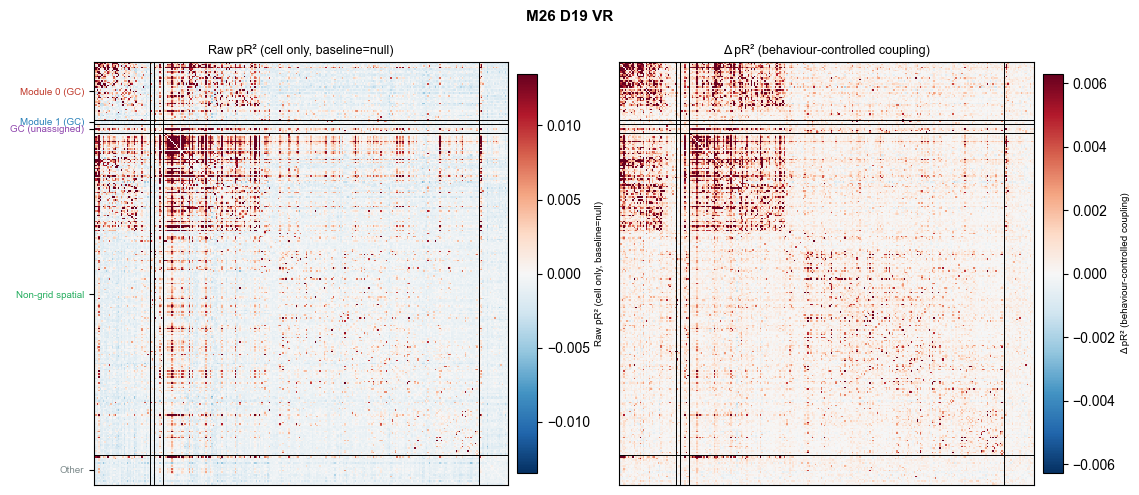

  RAW   within-cross: obs=0.0038  null=-0.0001±0.0023  p=0.0120
  DELTA within-cross: obs=0.0040  null=-0.0000±0.0023  p=0.0030


  Leiden(delta): 3 clusters, γ=0.00, Q=-0.000
  Leiden(raw):   31 clusters, γ=0.00, Q=-0.003
  Non-grid module assignment (Δ pR², direct): aggregate p=0.1379  7/239 cells individually significant (p<0.05, uncorrected)

===== M26 D19 OF1 =====


  280 cells total, 47 GC, 41 with known module (0/1)


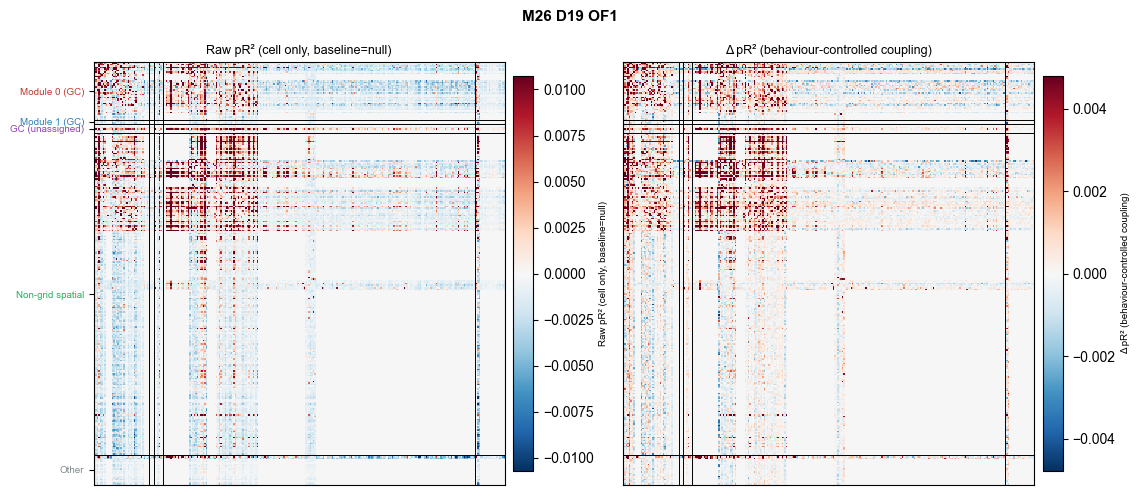

  RAW   within-cross: obs=0.0043  null=-0.0001±0.0024  p=0.0080
  DELTA within-cross: obs=0.0029  null=-0.0001±0.0017  p=0.0020


  Leiden(delta): 4 clusters, γ=0.00, Q=-0.003
  Leiden(raw):   13 clusters, γ=0.00, Q=-0.003
  Non-grid module assignment (Δ pR², direct): aggregate p=0.3676  0/239 cells individually significant (p<0.05, uncorrected)

===== M25 D25 OF1 =====


  108 cells total, 44 GC, 42 with known module (0/1)


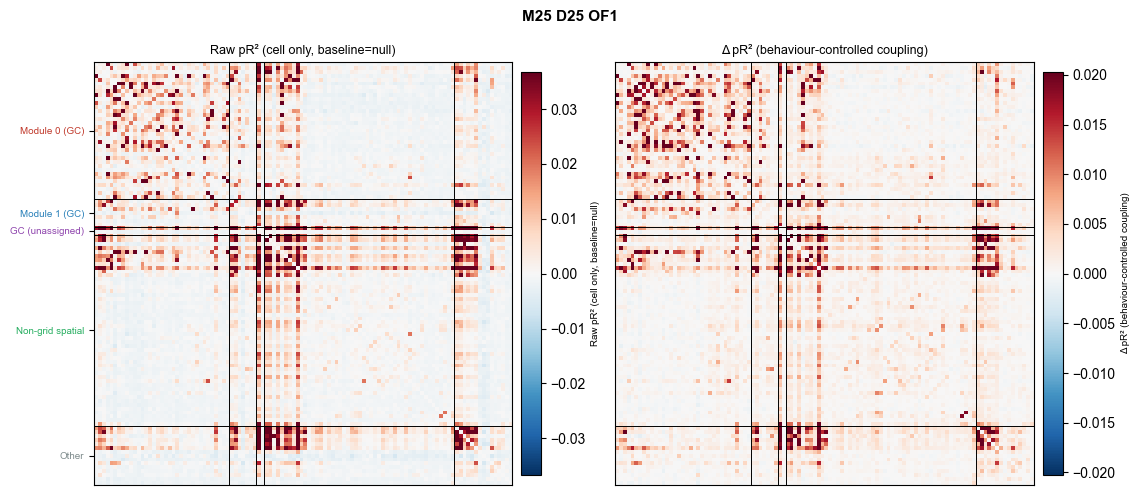

  RAW   within-cross: obs=0.0052  null=0.0000±0.0020  p=0.0040
  DELTA within-cross: obs=0.0048  null=-0.0000±0.0018  p=0.0010


  Leiden(delta): 1 clusters, γ=0.00, Q=-0.001
  Leiden(raw):   8 clusters, γ=0.00, Q=-0.004
  Non-grid module assignment (Δ pR², direct): aggregate p=0.0090  27/66 cells individually significant (p<0.05, uncorrected)

===== M21 D26 OF1 =====


  147 cells total, 32 GC, 28 with known module (0/1)


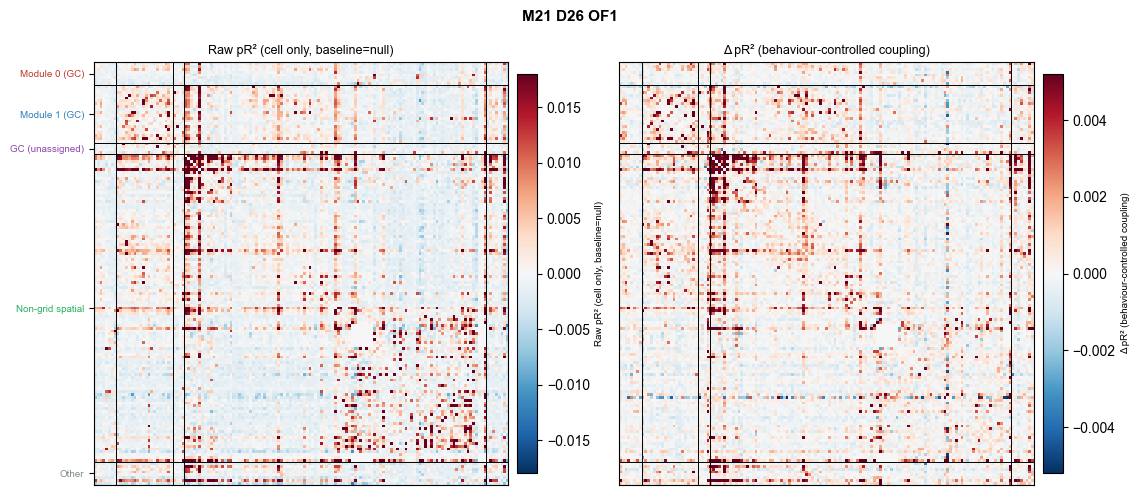

  RAW   within-cross: obs=0.0024  null=0.0000±0.0006  p=0.0010
  DELTA within-cross: obs=0.0007  null=0.0000±0.0002  p=0.0050


  Leiden(delta): 9 clusters, γ=0.00, Q=-0.003
  Leiden(raw):   11 clusters, γ=0.00, Q=-0.004
  Non-grid module assignment (Δ pR², direct): aggregate p=0.1089  7/119 cells individually significant (p<0.05, uncorrected)


In [5]:
all_results = []
matrices_store = {}

for cfg in SESSIONS:
    mouse, day = cfg['mouse'], cfg['day']
    mod_labels = get_module_labels(mouse, day)

    for session_type in cfg['sessions']:
        print(f'\n===== M{mouse} D{day} {session_type} =====')
        pw = load_pairwise(mouse, day, session_type)
        if pw is None:
            print('  no pairwise CSVs found, skipping')
            continue

        raw_sym, raw_dir, delta_sym, delta_dir, cell_ids = build_session_matrices(pw, session_type)
        n_gc  = sum(1 for cid in cell_ids if mod_labels.get(cid, {}).get('cell_type') == 'GC')
        n_mod = sum(1 for cid in cell_ids if mod_labels.get(cid, {}).get('module', -1) in (0, 1))
        print(f'  {len(cell_ids)} cells total, {n_gc} GC, {n_mod} with known module (0/1)')

        fig = plot_matrix_pair(raw_sym, delta_sym, cell_ids, mod_labels, f'M{mouse} D{day} {session_type}')
        fig.savefig(os.path.join(FIG_PATH, f'matrices_M{mouse}D{day}_{session_type}.pdf'),
                   dpi=200, bbox_inches='tight')
        plt.show()

        raw_stat   = within_cross_permtest(raw_sym, cell_ids, mod_labels)
        delta_stat = within_cross_permtest(delta_sym, cell_ids, mod_labels)
        if raw_stat:
            print(f'  RAW   within-cross: obs={raw_stat["observed"]:.4f}  '
                  f'null={raw_stat["null_mean"]:.4f}±{raw_stat["null_sd"]:.4f}  p={raw_stat["p"]:.4f}')
        if delta_stat:
            print(f'  DELTA within-cross: obs={delta_stat["observed"]:.4f}  '
                  f'null={delta_stat["null_mean"]:.4f}±{delta_stat["null_sd"]:.4f}  p={delta_stat["p"]:.4f}')

        leiden_delta, res_d, modQ_d = run_leiden(delta_sym)
        leiden_raw,   res_r, modQ_r = run_leiden(raw_sym)
        print(f'  Leiden(delta): {len(set(leiden_delta[leiden_delta >= 0]))} clusters, '
              f'γ={res_d:.2f}, Q={modQ_d:.3f}')
        print(f'  Leiden(raw):   {len(set(leiden_raw[leiden_raw >= 0]))} clusters, '
              f'γ={res_r:.2f}, Q={modQ_r:.3f}')

        assign_df, p_agg = assign_nongrid_cells(delta_sym, cell_ids, mod_labels)
        if assign_df is not None:
            sig = assign_df[assign_df.p_value < 0.05]
            print(f'  Non-grid module assignment (Δ pR², direct): aggregate p={p_agg:.4f}  '
                  f'{len(sig)}/{len(assign_df)} cells individually significant (p<0.05, uncorrected)')

        assign_leiden, purity = leiden_module_assignment(leiden_delta, cell_ids, mod_labels)

        all_results.append(dict(
            mouse=mouse, day=day, session_type=session_type,
            n_cells=len(cell_ids), n_gc=n_gc, n_mod_labelled=n_mod,
            raw_stat=raw_stat, delta_stat=delta_stat,
            leiden_delta_n=len(set(leiden_delta[leiden_delta >= 0])), leiden_delta_Q=modQ_d,
            assign_df=assign_df, p_agg=p_agg,
        ))
        matrices_store[(mouse, day, session_type)] = dict(
            raw_sym=raw_sym, delta_sym=delta_sym, cell_ids=cell_ids,
            leiden_delta=leiden_delta, mod_labels=mod_labels,
        )

## 5. Non-grid cell module assignment — closer look

Table of every non-grid-labelled cell's assignment for the largest session,
sorted by permutation p-value (most confidently module-attributable first).

In [6]:
best = max(all_results, key=lambda r: r['n_gc'])
print(f"M{best['mouse']} D{best['day']} {best['session_type']}  "
      f"(aggregate p={best['p_agg']:.4f})")
best['assign_df'].head(20)

M26 D19 VR  (aggregate p=0.1379)


,cluster_id,cell_type,assigned_module,mean_to_module0,mean_to_module1,margin,p_value
162,360,NG,1,0.000492,0.004071,0.003579,0.006993
101,284,NG,1,0.000333,0.001021,0.000688,0.007992
91,271,NG,1,0.000398,0.001961,0.001563,0.012987
175,376,NG,1,0.000135,0.000920,0.000785,0.016983
98,280,NG,1,0.000407,0.001170,0.000763,0.017982
164,362,NG,1,0.000282,0.001184,0.000902,0.027972
125,317,NG,1,0.000753,0.004047,0.003294,0.030969
169,369,NG,1,0.000290,0.002139,0.001850,0.054945
123,314,NG,1,0.000362,0.000791,0.000429,0.062937
170,370,NG,1,0.000295,0.001202,0.000907,0.068931


## 6. VR vs OF1 consistency (sessions recorded in both)

If module structure reflects genuine circuitry rather than a task-specific
epiphenomenon, a cell's Leiden(Δ pR²) cluster should be similar whether it was
recorded during VR or OF1.

In [7]:
dual = [cfg for cfg in SESSIONS if len(cfg['sessions']) > 1]
for cfg in dual:
    mouse, day = cfg['mouse'], cfg['day']
    key_vr, key_of = (mouse, day, 'VR'), (mouse, day, 'OF1')
    if key_vr not in matrices_store or key_of not in matrices_store:
        continue
    vr, of = matrices_store[key_vr], matrices_store[key_of]
    shared = sorted(set(vr['cell_ids']) & set(of['cell_ids']))
    print(f'M{mouse} D{day}: {len(shared)} cells recorded in both VR and OF1')

    idx_vr = {c: i for i, c in enumerate(vr['cell_ids'])}
    idx_of = {c: i for i, c in enumerate(of['cell_ids'])}
    lab_vr = np.array([vr['leiden_delta'][idx_vr[c]] for c in shared])
    lab_of = np.array([of['leiden_delta'][idx_of[c]] for c in shared])

    ari = adjusted_rand_score(lab_vr, lab_of)
    print(f'  Leiden(Δ pR²) cluster agreement VR vs OF1 -- Adjusted Rand Index = {ari:.3f}')
    print('  (ARI ~0 = no better than chance, ARI 1 = identical partitions)')

M26 D19: 280 cells recorded in both VR and OF1
  Leiden(Δ pR²) cluster agreement VR vs OF1 -- Adjusted Rand Index = 0.002
  (ARI ~0 = no better than chance, ARI 1 = identical partitions)


## 7. Summary across sessions

In [8]:
summary_rows = []
for r in all_results:
    summary_rows.append(dict(
        mouse=r['mouse'], day=r['day'], session_type=r['session_type'],
        n_cells=r['n_cells'], n_gc=r['n_gc'], n_mod_labelled=r['n_mod_labelled'],
        raw_within_minus_cross=r['raw_stat']['observed'] if r['raw_stat'] else np.nan,
        raw_p=r['raw_stat']['p'] if r['raw_stat'] else np.nan,
        delta_within_minus_cross=r['delta_stat']['observed'] if r['delta_stat'] else np.nan,
        delta_p=r['delta_stat']['p'] if r['delta_stat'] else np.nan,
        leiden_n_clusters=r['leiden_delta_n'], leiden_Q=r['leiden_delta_Q'],
        nongrid_p_aggregate=r['p_agg'],
    ))
summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(os.path.join(FIG_PATH, 'summary_within_cross_module.csv'), index=False)
summary_df

,mouse,day,session_type,n_cells,n_gc,n_mod_labelled,raw_within_minus_cross,raw_p,delta_within_minus_cross,delta_p,leiden_n_clusters,leiden_Q,nongrid_p_aggregate
0,26,19,VR,280,47,41,0.003807,0.011988,0.003976,0.002997,3,-0.000152,0.137862
1,26,19,OF1,280,47,41,0.004324,0.007992,0.002948,0.001998,4,-0.002922,0.367632
2,25,25,OF1,108,44,42,0.005152,0.003996,0.004803,0.000999,1,-0.000510,0.008991
3,21,26,OF1,147,32,28,0.002385,0.000999,0.000681,0.004995,9,-0.002890,0.108891
